# Mini-Project 2 – Uganda Tax Engine

**OOP with Python, Assignment 2 (Advent 2026)** · Wesonga John Collins

An extensible, testable tax calculator for rules administered by the Uganda Revenue Authority (URA): PAYE
(resident and non-resident), NSSF, Local Service Tax, VAT and corporate income tax, plus a `TaxPlanner`
extension. Reusable code lives in `src/a2/tax/`; boundary and property-based (hypothesis) tests are in `tests/`.

All money is `decimal.Decimal` inside a `Money` value object — never `float`.

## Sources and versions used

| Rule | Value used | Source (version) |
|---|---|---|
| Resident PAYE from **1 July 2026** | Nil to 335,000; 20% to 410,000; 15,000 + 25% to 485,000; 33,750 + 30% above; +10% above 10,000,000 | URA notice *Changes to PAYE return form following the Income Tax (Amendment) Act, 2026* (7 Sep 2026), https://ura.go.ug/en/changes-to-paye-return-form-following-the-income-tax-amendment-act-2026/ — Act assented 20 Aug 2026, effective 1 Jul 2026 |
| Resident PAYE, FY 2025/26 | Nil to 235,000; 10% to 335,000; 10,000 + 20% to 410,000; 25,000 + 30% above; +10% above 10,000,000 | URA PAYE rates page, https://ura.go.ug/?p=16453 |
| Non-resident PAYE | 10% to 335,000; 33,500 + 20% to 410,000; 48,500 + 30% above; +10% above 10,000,000 | URA PAYE rates page (above). The 2026 notice changes only the resident rate, so this is treated as unchanged (an inference) |
| VAT | 18% standard; 0% zero-rated (input VAT claimable); exempt supplies carry no VAT | URA VAT guidance, https://ura.go.ug/?p=38797 |
| Corporate income tax | 30% of chargeable income | Legal500, *Uganda tax system in a nutshell* (secondary; also the brief's baseline) |
| NSSF | 5% employee, 10% employer, on gross pay; employee share **not** PAYE-deductible | Brief's baseline; payroll guides disagree on deductibility, so a switch is provided |
| Local Service Tax | Configurable annual amount (UGX 5,000–100,000 by band), collected July–October, deducted **before** PAYE | Brief's baseline; the amount must be set per employee |
| Dividend withholding tax (extension) | 15% (resident individuals: 10% or 15%) | Grant Thornton Uganda, *Doing business in Uganda: taxation* |

Pay dates before **1 July 2025** have no schedule in this engine and raise `NoScheduleForDateError`.

## 0. Setup

In [1]:
from datetime import date
from decimal import Decimal

import matplotlib.pyplot as plt
import pandas as pd

from a2.tax.cit import CorporateIncomeTax
from a2.tax.context import TaxContext
from a2.tax.errors import InvalidIncomeError, NoScheduleForDateError, TaxError
from a2.tax.money import Money
from a2.tax.payroll import NSSF, PAYE, LocalServiceTax, PayrollPipeline
from a2.tax.planner import TaxPlanner
from a2.tax.schedules import NON_RESIDENT, RESIDENT, URA_PAYE
from a2.tax.vat import EXEMPT, PURCHASE, SALE, STANDARD, VAT, ZERO_RATED, Invoice

PAY_DATE = date(2026, 8, 31)          # a pay date under the new (1 July 2026) resident schedule
OLD_DATE = date(2026, 6, 30)          # last day of FY 2025/26
pd.set_option("display.max_colwidth", 60)

def ugx(m: Money) -> str:
    return f"{m.rounded().amount:,.0f}"

## 1. Money: why not float?

A concrete failure: the very first shilling above the PAYE threshold. With floats, the taxable part of
UGX 335,000.10 is not 0.10, and repeated additions drift away from exact totals.

In [2]:
income_f = 335_000.10
print("float:   taxable part above 335,000 =", income_f - 335_000, " -> 20% =", (income_f - 335_000) * 0.20)
income_d = Money("335000.10")
print("Decimal: taxable part above 335,000 =", (income_d - Money(335_000)).amount,
      " -> 20% =", ((income_d - Money(335_000)) * Decimal("0.20")).amount)

running = 0.0
for _ in range(10):
    running += 0.1                      # e.g. ten payments of UGX 0.1 added one by one
print("\nTen payments of 0.1 added as floats equal 1.0?", running == 1.0, f"({running!r})")
print("Ten payments of 0.1 added as Money equal 1?   ", sum([Money("0.1")] * 10, Money.zero()) == Money(1))

print("\nPython round() on float uses 'banker's rounding': round(2.5) =", round(2.5), ", round(0.5) =", round(0.5))
print("Money rounds half-up explicitly:          ", Money("2.5").rounded(), ",", Money("0.5").rounded())
try:
    Money(0.1)
except TypeError as err:
    print("\nMoney(0.1) ->", type(err).__name__, ":", err)

float:   taxable part above 335,000 = 0.09999999997671694  -> 20% = 0.01999999999534339
Decimal: taxable part above 335,000 = 0.10  -> 20% = 0.0200

Ten payments of 0.1 added as floats equal 1.0? False (0.9999999999999999)
Ten payments of 0.1 added as Money equal 1?    True

Python round() on float uses 'banker's rounding': round(2.5) = 2 , round(0.5) = 0
Money rounds half-up explicitly:           UGX 3 , UGX 1

Money(0.1) -> TypeError : float is not allowed for money; use int, str or Decimal


## 2. PAYE schedules and the band edges

In [3]:
schedules = {"Resident, from 1 Jul 2026": URA_PAYE.lookup(RESIDENT, PAY_DATE),
             "Resident, FY 2025/26": URA_PAYE.lookup(RESIDENT, OLD_DATE),
             "Non-resident": URA_PAYE.lookup(NON_RESIDENT, PAY_DATE)}
edges = [335_000, 335_001, 410_000, 485_000, 10_000_000, 10_000_001]
pd.DataFrame({name: {f"{e:,}": s.tax(Money(e))[0].amount for e in edges} for name, s in schedules.items()}) \
  .rename_axis("monthly chargeable income (UGX)")

,"Resident, from 1 Jul 2026","Resident, FY 2025/26",Non-resident
monthly chargeable income (UGX),,,
"335,000",0,10000.00,33500.00
"335,001",0.20,10000.20,33500.20
"410,000",15000.00,25000.00,48500.00
"485,000",33750.00,47500.00,71000.00
"10,000,000",2888250.00,2902000.00,2925500.00
"10,000,001",2888250.40,2902000.40,2925500.40


In [4]:
total, lines = schedules["Resident, from 1 Jul 2026"].tax(Money(12_000_000))
print("Breakdown of PAYE on UGX 12,000,000 (resident, from 1 July 2026):")
for label, amount in lines:
    print(f"  {label:<40} {amount.amount:>14,.2f}")
print(f"  {'total':<40} {total.amount:>14,.2f}")

Breakdown of PAYE on UGX 12,000,000 (resident, from 1 July 2026):
  20% on 335,000–410,000                        15,000.00
  25% on 410,000–485,000                        18,750.00
  30% above 485,000                          3,454,500.00
  10% surcharge above 10,000,000               200,000.00
  total                                      3,688,250.00


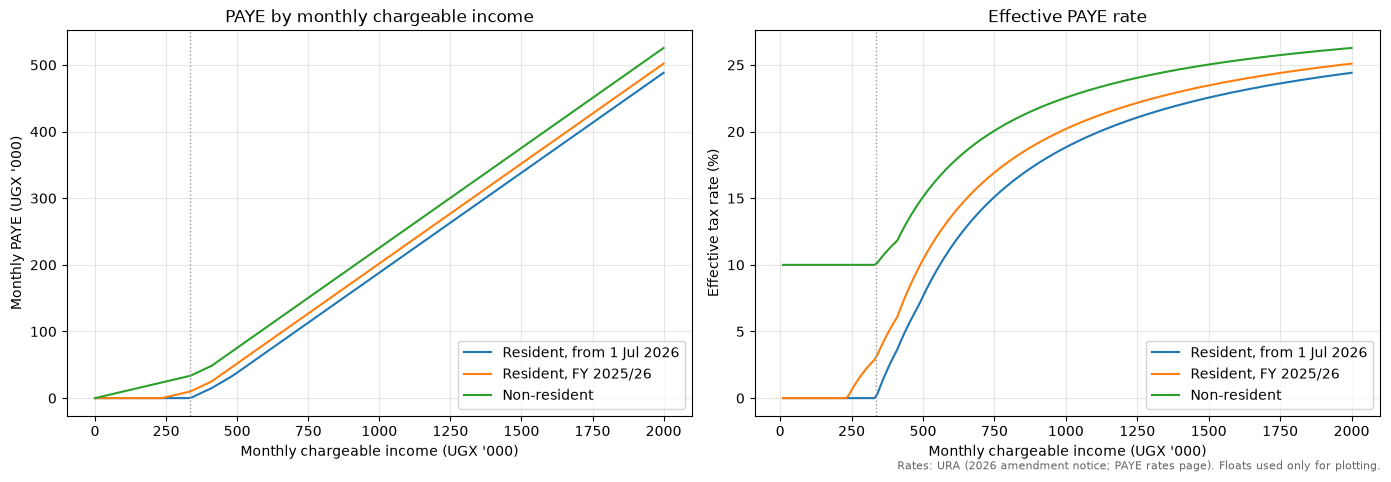

In [5]:
incomes = list(range(0, 2_000_001, 10_000))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, s in schedules.items():
    taxes = [s.tax(Money(i))[0].amount for i in incomes]
    axes[0].plot([i / 1000 for i in incomes], [float(t) / 1000 for t in taxes], label=name)
    axes[1].plot([i / 1000 for i in incomes[1:]],
                 [float(t / Decimal(i)) * 100 for t, i in zip(taxes[1:], incomes[1:])], label=name)
axes[0].set_ylabel("Monthly PAYE (UGX '000)")
axes[0].set_title("PAYE by monthly chargeable income")
axes[1].set_ylabel("Effective tax rate (%)")
axes[1].set_title("Effective PAYE rate")
for ax in axes:
    ax.set_xlabel("Monthly chargeable income (UGX '000)")
    ax.axvline(335, color="0.6", ls=":", lw=1)
    ax.legend(); ax.grid(alpha=0.3)
fig.text(0.99, 0.01, "Rates: URA (2026 amendment notice; PAYE rates page). Floats used only for plotting.",
         ha="right", fontsize=8, color="0.4")
fig.tight_layout()
plt.show()

The table reproduces every constant in URA's formulas (15,000 and 33,750 for the new resident schedule; 10,000 and 25,000 for the old one; 33,500 and 48,500 for non-residents), which is a check that the bands are encoded correctly. The 2026 amendment lowers PAYE for every resident earning more than UGX 235,000 a month: anyone between 235,000 and 335,000 now pays nothing, the saving is a constant UGX 10,000 a month between 335,000 and 410,000, it rises to UGX 13,750 at 485,000, and it stays at 13,750 for all higher incomes because both schedules then tax each extra shilling at 30%. In relative terms the change matters most at the bottom: the effective rate at 500,000 falls from 10.4 % to 7.7 %, while at 2 million it falls only from 25.1 % to 24.4 %. Non-residents pay 10 % from the first shilling and remain the most heavily taxed at every income (UGX 37,250 more than a resident at 10 million).

## 3. Payroll pipeline: NSSF, Local Service Tax, PAYE and net pay

**Order of deductions and why:**

1. **NSSF** (5% employee, 10% employer) on total gross pay — a statutory contribution that does not depend on
   income tax, so it is computed first from gross.
2. **Local Service Tax** — this month's instalment of the configured annual amount (July–October). The brief's
   baseline treats it as a deduction applied before PAYE, so it reduces chargeable income.
3. **PAYE** on chargeable income = gross + allowances − LST, using the schedule in force on the pay date for the
   employee's residency. Employee NSSF is not deducted (the majority position; `PAYE(nssf_deductible=True)`
   switches this).
4. **Net pay** = gross − employee NSSF − LST − PAYE. Employer NSSF is shown as a cost, not deducted from pay.

In [6]:
employees = [
    ("Clerk (resident)", RESIDENT, 400_000, 0, 10_000),
    ("Engineer (resident)", RESIDENT, 1_000_000, 200_000, 60_000),
    ("Director (resident)", RESIDENT, 12_000_000, 0, 100_000),
    ("Consultant (non-resident)", NON_RESIDENT, 1_000_000, 200_000, 60_000),
]
slips = {}
for name, residency, gross, allowances, annual_lst in employees:
    pipeline = PayrollPipeline(PAYE(), NSSF(), LocalServiceTax(Money(annual_lst)))
    ctx = TaxContext(on=PAY_DATE, residency=residency, gross_pay=Money(gross), allowances=Money(allowances))
    slips[name] = pipeline.run(ctx)
    assert slips[name].net_pay + slips[name].nssf_employee + slips[name].lst + slips[name].paye == slips[name].total_gross

payslips = pd.DataFrame({name: {label: ugx(v) for label, v in slip.rows()} for name, slip in slips.items()})
payslips.loc["Schedule"] = [slip.schedule for slip in slips.values()]
payslips

,Clerk (resident),Engineer (resident),Director (resident),Consultant (non-resident)
Total gross pay (incl. allowances),"400,000","1,200,000","12,000,000","1,200,000"
less NSSF (employee 5%),"20,000","60,000","600,000","60,000"
less Local Service Tax,"2,500","15,000","25,000","15,000"
Chargeable income for PAYE,"397,500","1,185,000","11,975,000","1,185,000"
less PAYE,"12,500","243,750","3,678,250","281,000"
Net pay,"365,000","881,250","7,696,750","844,000"
"Employer NSSF (10%, cost to employer)","40,000","120,000","1,200,000","120,000"
Schedule,"Resident PAYE, from 1 July 2026","Resident PAYE, from 1 July 2026","Resident PAYE, from 1 July 2026",Non-resident PAYE


The pipeline applies the documented order, and every payslip balances (net pay + NSSF + LST + PAYE = gross, checked by an `assert`). The clerk on UGX 400,000 pays only UGX 12,500 PAYE because the first 335,000 is now tax-free, and LST (2,500) slightly reduces the chargeable income. The engineer's allowances are taxed like salary: PAYE is charged on 1,185,000 (1,200,000 less the August LST instalment), giving UGX 243,750 and a net pay of UGX 881,250. The director's PAYE of UGX 3,678,250 is about 31 % of gross pay because income above 10 million carries the extra 10 %. The non-resident consultant with the same pay as the engineer pays UGX 37,250 more PAYE (281,000), the gap that comes from the non-resident schedule taxing the first 335,000 at 10 %. Employer NSSF (10 %) is a cost on top of gross pay and does not reduce what the employee receives.

## 4. VAT over a month's invoices

In [7]:
invoices = (
    Invoice("S-001", SALE, STANDARD, Money(12_000_000)),
    Invoice("S-002", SALE, STANDARD, Money(5_900_000), vat_inclusive=True),
    Invoice("S-003", SALE, ZERO_RATED, Money(8_000_000)),          # export
    Invoice("S-004", SALE, EXEMPT, Money(2_500_000)),
    Invoice("P-001", PURCHASE, STANDARD, Money(7_000_000)),
    Invoice("P-002", PURCHASE, STANDARD, Money(1_180_000), vat_inclusive=True),
    Invoice("P-003", PURCHASE, EXEMPT, Money(900_000)),
)
vat = VAT()
rows = []
for inv in invoices:
    net, tax = vat.split(inv)
    rows.append({"invoice": inv.number, "kind": inv.kind, "supply": inv.supply,
                 "amount as invoiced": ugx(inv.amount), "VAT-inclusive?": inv.vat_inclusive,
                 "net value": ugx(net), "VAT": ugx(tax)})
display(pd.DataFrame(rows).set_index("invoice"))

result = vat.calculate(TaxContext(on=PAY_DATE, invoices=invoices))
for label, amount in result.lines:
    print(f"{label:<45} UGX {ugx(amount):>12}")

,kind,supply,amount as invoiced,VAT-inclusive?,net value,VAT
invoice,,,,,,
S-001,sale,standard,"12,000,000",False,"12,000,000","2,160,000"
S-002,sale,standard,"5,900,000",True,"5,000,000","900,000"
S-003,sale,zero-rated,"8,000,000",False,"8,000,000",0
S-004,sale,exempt,"2,500,000",False,"2,500,000",0
P-001,purchase,standard,"7,000,000",False,"7,000,000","1,260,000"
P-002,purchase,standard,"1,180,000",True,"1,000,000","180,000"
P-003,purchase,exempt,"900,000",False,"900,000",0


output VAT on sales                           UGX    3,060,000
input VAT on purchases                        UGX    1,440,000
net VAT payable                               UGX    1,620,000


In [8]:
# URA's own worked example as a check: output 270, input 180 -> 90 payable.
check = vat.calculate(TaxContext(on=PAY_DATE, invoices=(Invoice("A", SALE, STANDARD, Money(1_500)),
                                                        Invoice("B", PURCHASE, STANDARD, Money(1_000)))))
print("URA example ->", check.amount)
assert check.amount == Money(90)

URA example -> UGX 90


Output VAT comes only from the two standard-rated sales: 18 % of 12,000,000 and the VAT contained in the VAT-inclusive invoice of 5,900,000 (5,900,000 × 18/118 = 900,000), a total of UGX 3,060,000. The export (zero-rated) and the exempt sale carry no output VAT. Input VAT of UGX 1,440,000 comes from the two standard-rated purchases (again extracting VAT from the inclusive one), and the exempt purchase carries none. The business therefore pays UGX 1,620,000 net to URA. The difference between zero-rated and exempt matters for the seller: a zero-rated exporter still recovers the VAT on its purchases, while an exempt supplier cannot charge VAT and, under the law, cannot claim the related input VAT. This engine does not apportion input VAT between taxable and exempt sales, which a real VAT return would require.

## 5. Corporate income tax

In [9]:
cit = CorporateIncomeTax()
companies = {"Profitable company": (500_000_000, 320_000_000), "Loss-making company": (80_000_000, 95_000_000)}
for name, (revenue, deductions) in companies.items():
    r = cit.calculate(TaxContext(on=PAY_DATE, revenue=Money(revenue), allowable_deductions=Money(deductions)))
    print(f"{name}: tax = {r.amount}")
    for label, amount in r.lines:
        print(f"    {label:<40} {ugx(amount):>14}")

Profitable company: tax = UGX 54,000,000
    revenue                                     500,000,000
    allowable deductions                        320,000,000
    chargeable income                           180,000,000
    tax at 30%                                   54,000,000
Loss-making company: tax = UGX 0
    revenue                                      80,000,000
    allowable deductions                         95,000,000
    tax loss (carry-forward not modelled)        15,000,000


## 6. Validation and errors: nothing fails silently

Every invalid input raises a specific exception from the hierarchy `TaxError` → `InvalidIncomeError`,
`NoScheduleForDateError`.

In [10]:
attempts = {
    "float amount": lambda: Money(500000.0),
    "negative gross pay": lambda: TaxContext(on=PAY_DATE, gross_pay=Money(-1)),
    "plain int instead of Money": lambda: TaxContext(on=PAY_DATE, gross_pay=500_000),
    "unknown residency": lambda: TaxContext(on=PAY_DATE, residency="tourist", gross_pay=Money(1)),
    "pay date before any schedule": lambda: PAYE().calculate(TaxContext(on=date(2024, 1, 31), gross_pay=Money(500_000))),
    "PAYE without gross pay": lambda: PAYE().calculate(TaxContext(on=PAY_DATE)),
    "VAT with no invoices": lambda: VAT().calculate(TaxContext(on=PAY_DATE)),
    "LST larger than a tiny salary": lambda: PayrollPipeline(PAYE(), NSSF(), LocalServiceTax(Money(100_000)))
                                             .run(TaxContext(on=PAY_DATE, gross_pay=Money(10_000))),
}
for label, attempt in attempts.items():
    try:
        attempt()
        print(f"{label:<32} -> NO ERROR (unexpected)")
    except (TaxError, TypeError) as err:
        print(f"{label:<32} -> {type(err).__name__}: {err}")

float amount                     -> TypeError: float is not allowed for money; use int, str or Decimal
negative gross pay               -> InvalidIncomeError: gross_pay cannot be negative: Money('-1', 'UGX')
plain int instead of Money       -> InvalidIncomeError: gross_pay must be a Money value, got int
unknown residency                -> InvalidIncomeError: residency must be 'resident' or 'non-resident'
pay date before any schedule     -> NoScheduleForDateError: no resident PAYE schedule covers 2024-01-31
PAYE without gross pay           -> InvalidIncomeError: gross_pay is required for this tax
VAT with no invoices             -> InvalidIncomeError: VAT needs at least one invoice in the context
LST larger than a tiny salary    -> InvalidIncomeError: deductions exceed gross pay; check the inputs


## 7. Extension B – `TaxPlanner`: salary versus dividend

An owner-manager can take a month's pre-tax profit as **salary** (deductible for the company, so no corporate
tax, but employee NSSF, employer NSSF and PAYE apply) or as a **dividend** (the company pays 30% corporate tax,
then 15% withholding tax on the dividend, treated as final). The planner composes the existing `PayrollPipeline`
and `CorporateIncomeTax` objects. Simplifications: one month, no other income, no LST, no carry-forward losses.

In [11]:
planner = TaxPlanner(PayrollPipeline(PAYE(), NSSF()), CorporateIncomeTax(), dividend_wht_rate=Decimal("0.15"))
example = planner.compare(Money(3_300_000), PAY_DATE)
for scenario in (example.salary, example.dividend):
    taxes = ", ".join(f"{label} {ugx(amount)}" for label, amount in scenario.taxes)
    print(f"{scenario.name:<9} owner receives UGX {ugx(scenario.owner_receives):>10}   ({taxes})")
print(f"Better: {example.better.name}, by UGX {ugx(example.difference)}")

Salary    owner receives UGX  2,061,750   (employer NSSF 300,000, employee NSSF 150,000, Local Service Tax 0, PAYE 788,250)
Dividend  owner receives UGX  1,963,500   (corporate income tax 990,000, dividend withholding tax 346,500)
Better: Salary, by UGX 98,250


Lowest monthly profit (on a UGX 500,000 grid) where the dividend route pays the owner more: 12,000,000


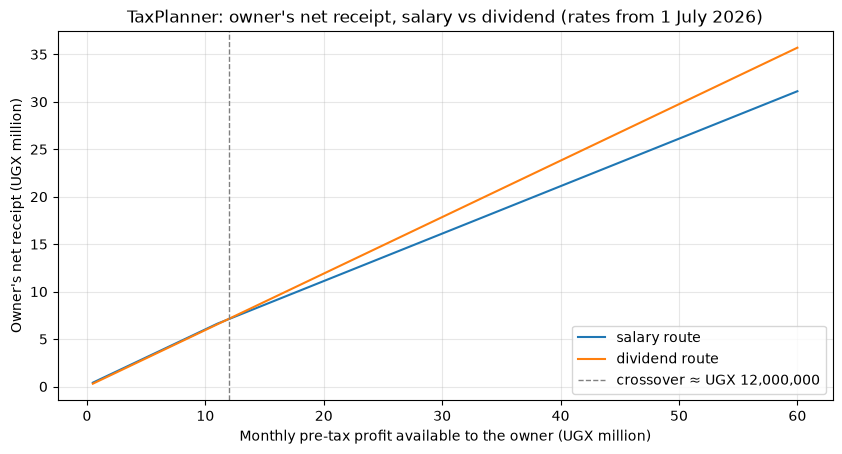

In [12]:
profits = [Money(p) for p in range(500_000, 60_000_001, 500_000)]
comparisons = [planner.compare(p, PAY_DATE) for p in profits]
crossover = next((c.profit for c in comparisons if c.better is c.dividend), None)
print("Lowest monthly profit (on a UGX 500,000 grid) where the dividend route pays the owner more:",
      ugx(crossover) if crossover else "none in range")

x = [float(c.profit.amount) / 1e6 for c in comparisons]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(x, [float(c.salary.owner_receives.amount) / 1e6 for c in comparisons], label="salary route")
ax.plot(x, [float(c.dividend.owner_receives.amount) / 1e6 for c in comparisons], label="dividend route")
if crossover:
    ax.axvline(float(crossover.amount) / 1e6, color="0.5", ls="--", lw=1, label=f"crossover ≈ UGX {ugx(crossover)}")
ax.set_xlabel("Monthly pre-tax profit available to the owner (UGX million)")
ax.set_ylabel("Owner's net receipt (UGX million)")
ax.set_title("TaxPlanner: owner's net receipt, salary vs dividend (rates from 1 July 2026)")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

At UGX 3.3 million of monthly profit the salary route leaves the owner UGX 98,250 more than the dividend route. The dividend route has a flat burden: 30 % corporate tax and then 15 % withholding on the remaining 70 %, 40.5 % in total at every profit level. The salary route starts lighter, because the first 335,000 of salary is tax-free and the lower bands are below 30 %, but each extra shilling of profit eventually costs employer NSSF (1/11 of the profit), employee NSSF, and PAYE at 30 % and then 40 % above a salary of 10 million. That makes the marginal burden of salary about 50 % at high incomes, above the dividend's 40.5 %, so the routes cross: on a UGX 500,000 grid the dividend route first pays more at a monthly profit of UGX 12 million. The comparison is deliberately simple: it is one month, it ignores the owner's other income, LST, the 10 % dividend rate for listed companies and the fact that NSSF contributions are savings returned to the member rather than a pure cost.

## 8. Discussion

### Why is float unsafe for tax computation?

A float stores numbers in binary, so most decimal amounts, such as 0.10, cannot be represented exactly. Section 1 shows the consequence at a PAYE band edge: with floats, the part of UGX 335,000.10 above the 335,000 threshold comes out as 0.09999999997671694 rather than 0.10, and 20 % of it as 0.0199999999953 instead of 0.02. Adding ten payments of 0.1 one by one gives 0.9999999999999999, not 1.0, so a payroll total can fail an exact equality check with the figure on a return. Rounding is also a trap: Python's `round()` on floats uses round-half-to-even, so `round(2.5)` is 2 and `round(0.5)` is 0, a policy that must be chosen deliberately rather than inherited by accident. In tax work these tiny errors matter, because band edges and thresholds are compared exactly, totals must reconcile to the shilling across thousands of payslips and invoices, and the results have legal force. `decimal.Decimal` represents decimal amounts exactly, and the `Money` class refuses floats outright (`Money(0.1)` raises `TypeError`), keeps calculations exact, and rounds only once, half-up to whole shillings, at the end of each tax result.

### Where is inheritance justified, and where was it deliberately avoided?

Inheritance is used where several classes genuinely share one interface. Every tax (`PAYE`, `NSSF`, `LocalServiceTax`, `VAT`, `CorporateIncomeTax`) is a subclass of the abstract `Tax` class with a single method, `calculate(ctx) -> TaxResult`. The abstract method forces every new tax to provide it, and the pipeline and planner can treat taxes uniformly. The exception hierarchy also uses inheritance (`InvalidIncomeError` and `NoScheduleForDateError` are both `TaxError`s), so callers can catch one family or one specific case.

Inheritance was deliberately avoided in three places. Resident and non-resident PAYE are not two classes: they differ only in their numbers, so they are two `ProgressiveSchedule` objects in a dated registry, and the July 2026 rate change was added as data without touching any code. `Money` wraps a `Decimal` instead of subclassing it, because a subclass would inherit every `Decimal` operation, including ones that accept other numeric types, and could not guarantee that floats are refused. Finally, `PayrollPipeline` and `TaxPlanner` are built by composition: they hold tax objects and call them in order, rather than inheriting from them, so each tax can be tested and replaced on its own.